In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow import keras

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully!")


TensorFlow version: 2.21.0
Libraries loaded successfully!


# Stock Market Analysis & Price Prediction Using Python and LSTM

## Project Overview

This project analyzes historical Apple (AAPL) stock price data and develops a Long Short-Term Memory (LSTM) neural network to model historical closing-price patterns.

The project includes:

- Exploratory Data Analysis (EDA)
- Daily return analysis
- Moving averages
- Volatility analysis
- LSTM time-series modeling
- Model evaluation using MAE and RMSE
- Comparison with a simple baseline model
- Actual vs predicted price visualization

> **Note:** This project is for educational and analytical purposes. Stock prices are influenced by many factors, and the model should not be interpreted as reliable financial or investment advice.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [5]:
ticker = "AAPL"

df = yf.download(
    ticker,
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=False
)

df.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2015-01-02,24.171759,27.332500,27.860001,26.837500,27.847500,212818400
2015-01-05,23.490805,26.562500,27.162500,26.352501,27.072500,257142000
2015-01-06,23.493006,26.565001,26.857500,26.157499,26.635000,263188400
2015-01-07,23.822432,26.937500,27.049999,26.674999,26.799999,160423600
2015-01-08,24.737755,27.972500,28.037500,27.174999,27.307501,237458000


In [6]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (2766, 6)

Columns:
MultiIndex([('Adj Close', 'AAPL'),
            (    'Close', 'AAPL'),
            (     'High', 'AAPL'),
            (      'Low', 'AAPL'),
            (     'Open', 'AAPL'),
            (   'Volume', 'AAPL')],
           names=['Price', 'Ticker'])

Missing values:
Price      Ticker
Adj Close  AAPL      0
Close      AAPL      0
High       AAPL      0
Low        AAPL      0
Open       AAPL      0
Volume     AAPL      0
dtype: int64


In [7]:
# Flatten yfinance's multi-level columns if necessary
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df.head()

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2015-01-02,24.171759,27.332500,27.860001,26.837500,27.847500,212818400
2015-01-05,23.490805,26.562500,27.162500,26.352501,27.072500,257142000
2015-01-06,23.493006,26.565001,26.857500,26.157499,26.635000,263188400
2015-01-07,23.822432,26.937500,27.049999,26.674999,26.799999,160423600
2015-01-08,24.737755,27.972500,28.037500,27.174999,27.307501,237458000


In [8]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2766 entries, 2015-01-02 to 2025-12-31
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  2766 non-null   float64
 1   Close      2766 non-null   float64
 2   High       2766 non-null   float64
 3   Low        2766 non-null   float64
 4   Open       2766 non-null   float64
 5   Volume     2766 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 151.3 KB


In [9]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2766 entries, 2015-01-02 to 2025-12-31
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  2766 non-null   float64
 1   Close      2766 non-null   float64
 2   High       2766 non-null   float64
 3   Low        2766 non-null   float64
 4   Open       2766 non-null   float64
 5   Volume     2766 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 151.3 KB


In [10]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Close"])

plt.title("Apple (AAPL) Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")

plt.grid(True)
plt.show()

KeyError: 'Date'

<Figure size 1400x600 with 0 Axes>

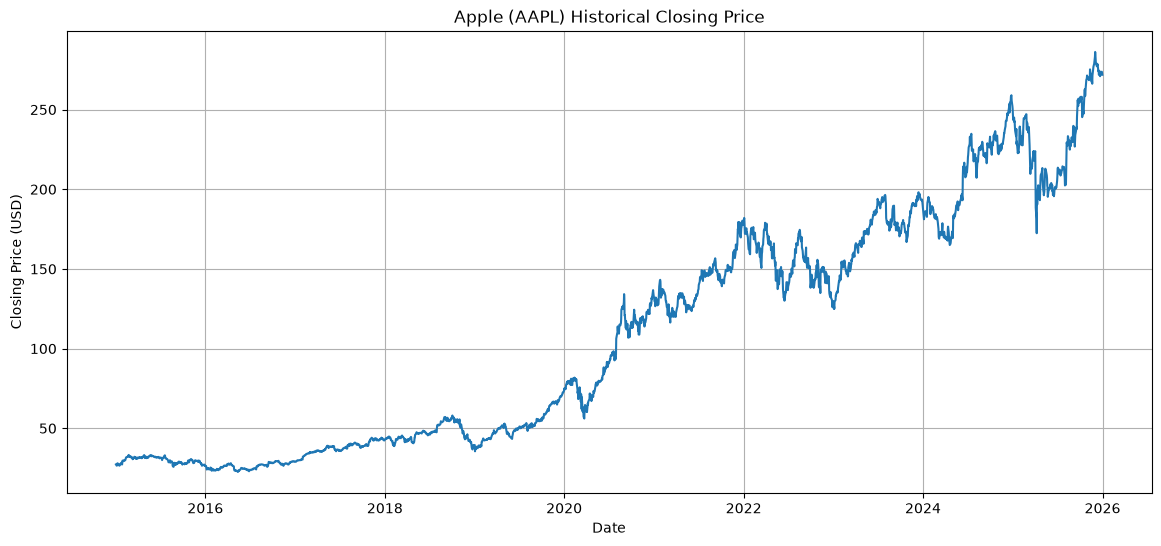

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Close"])

plt.title("Apple (AAPL) Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")

plt.grid(True)
plt.show()

In [12]:
df["Daily_Return"] = df["Close"].pct_change()

df[["Close", "Daily_Return"]].head(10)

Price,Close,Daily_Return
Date,,
2015-01-02,27.332500,NaN
2015-01-05,26.562500,-0.028172
2015-01-06,26.565001,0.000094
2015-01-07,26.937500,0.014022
2015-01-08,27.972500,0.038422
2015-01-09,28.002501,0.001073
2015-01-12,27.312500,-0.024641
2015-01-13,27.555000,0.008879
2015-01-14,27.450001,-0.003811


In [13]:
df["Daily_Return"] = df["Close"].pct_change()

df[["Close", "Daily_Return"]].head(10)

Price,Close,Daily_Return
Date,,
2015-01-02,27.332500,NaN
2015-01-05,26.562500,-0.028172
2015-01-06,26.565001,0.000094
2015-01-07,26.937500,0.014022
2015-01-08,27.972500,0.038422
2015-01-09,28.002501,0.001073
2015-01-12,27.312500,-0.024641
2015-01-13,27.555000,0.008879
2015-01-14,27.450001,-0.003811


In [14]:
print("Average daily return:", df["Daily_Return"].mean())
print("Daily return volatility:", df["Daily_Return"].std())


Average daily return: 0.0009960902918530552
Daily return volatility: 0.01817665497131035


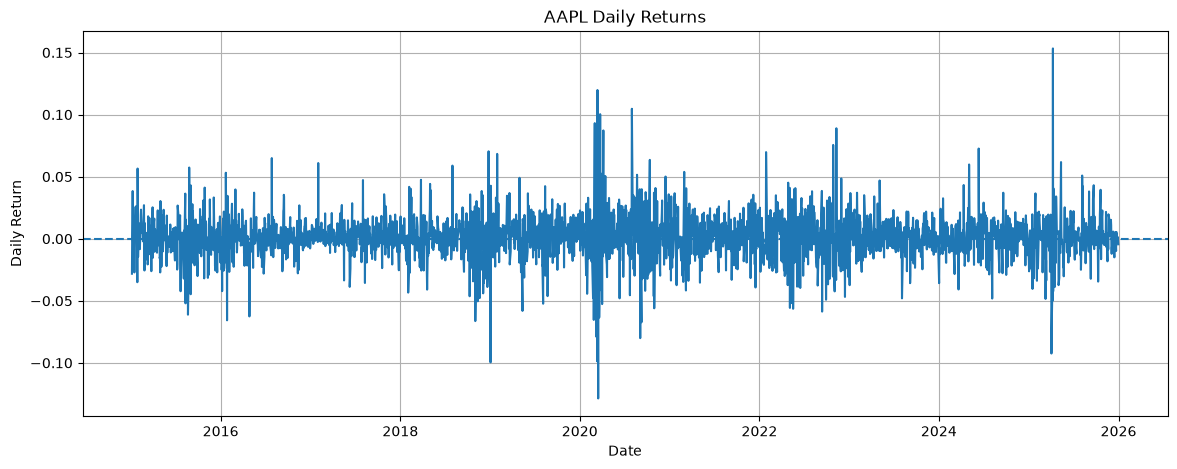

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["Daily_Return"])

plt.title("AAPL Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")

plt.axhline(0, linestyle="--")

plt.grid(True)
plt.show()

In [16]:
df["MA20"] = df["Close"].rolling(window=20).mean()
df["MA50"] = df["Close"].rolling(window=50).mean()

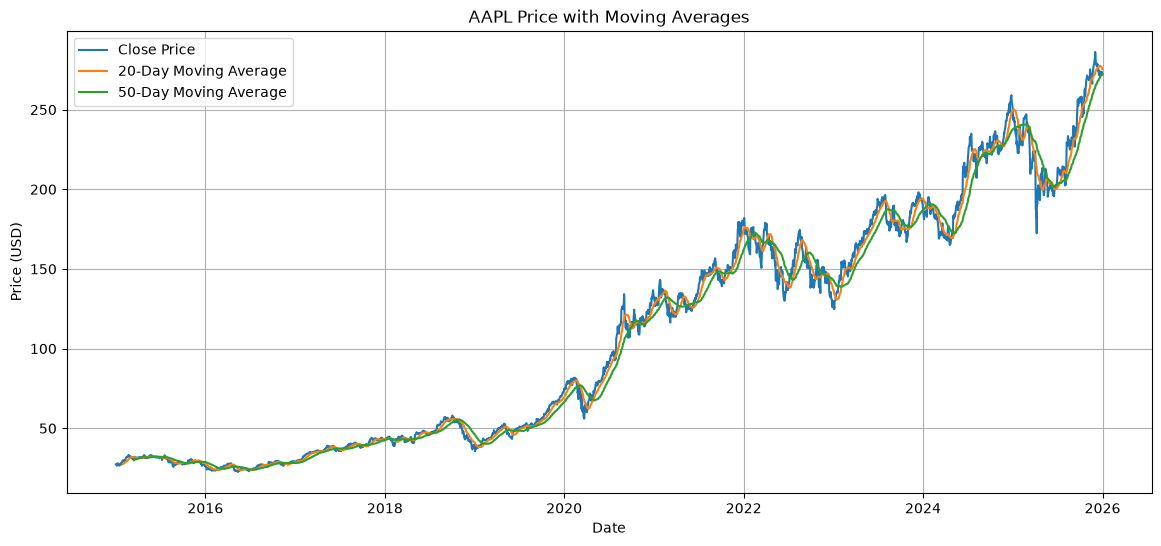

In [17]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Close"], label="Close Price")
plt.plot(df.index, df["MA20"], label="20-Day Moving Average")
plt.plot(df.index, df["MA50"], label="50-Day Moving Average")

plt.title("AAPL Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(True)
plt.show()

In [18]:
df = df.dropna().copy()

print("Rows remaining:", len(df))

Rows remaining: 2717


In [19]:
prices = df["Close"].values.reshape(-1, 1)

print("Number of price observations:", len(prices))

Number of price observations: 2717


In [20]:
train_size = int(len(prices) * 0.8)

train_data = prices[:train_size]
test_data = prices[train_size:]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

Training observations: 2173
Testing observations: 544


In [21]:
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

print("Minimum scaled value:", train_scaled.min())
print("Maximum scaled value:", train_scaled.max())

Minimum scaled value: 0.0
Maximum scaled value: 0.9999999999999998


In [22]:
lookback = 60

X_train = []
y_train = []

for i in range(lookback, len(train_scaled)):
    X_train.append(train_scaled[i-lookback:i, 0])
    y_train.append(train_scaled[i, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (2113, 60)
y_train shape: (2113,)


In [23]:
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

print("X_train shape:", X_train.shape)

X_train shape: (2113, 60, 1)


In [24]:
model = keras.Sequential([
    keras.layers.Input(shape=(lookback, 1)),

    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.LSTM(64),

    keras.layers.Dense(32),
    keras.layers.Dropout(0.2),

    keras.layers.Dense(1)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,033 (203.25 KB)

 Trainable params: 52,033 (203.25 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

In [26]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 128ms/step - loss: 0.0133 - val_loss: 0.0029
Epoch 2/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - loss: 0.0026 - val_loss: 0.0010
Epoch 3/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - loss: 0.0022 - val_loss: 0.0011
Epoch 4/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - loss: 0.0022 - val_loss: 7.4363e-04
Epoch 5/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - loss: 0.0022 - val_loss: 7.2663e-04
Epoch 6/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.0021 - val_loss: 7.0446e-04
Epoch 7/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - loss: 0.0019 - val_loss: 0.0026
Epoch 8/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - loss: 0.0017 - val_loss: 0.0026
Epoch 9/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - loss: 0.0016 - val_loss: 0.0014
Epoch 10/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - loss: 0.0016 - val_loss: 6.0092e-04
Epoch 11/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - loss: 0.0017 - val_loss: 0.0016
Epoch 12/20
60/60 ━━━━━━━━━━━━━━━━━━━━

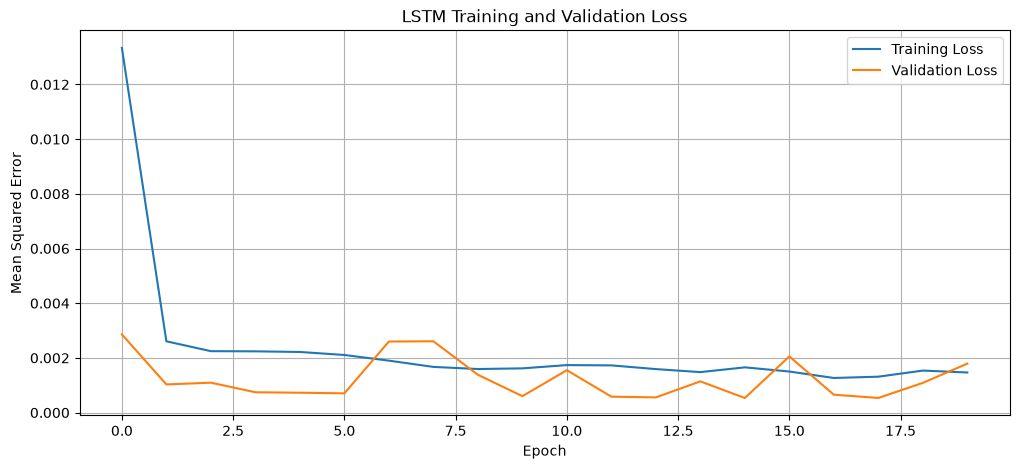

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.grid(True)
plt.show()

In [28]:
# Combine the last 60 training prices with the test prices
combined_data = np.concatenate((train_data[-lookback:], test_data))

# Scale using the scaler fitted on training data
combined_scaled = scaler.transform(combined_data)

X_test = []

for i in range(lookback, len(combined_scaled)):
    X_test.append(combined_scaled[i-lookback:i, 0])

X_test = np.array(X_test)

# Reshape for LSTM
X_test = X_test.reshape(
    X_test.shape[0],
    X_test.shape[1],
    1
)

print("X_test shape:", X_test.shape)

X_test shape: (544, 60, 1)


In [29]:
predictions_scaled = model.predict(X_test)

print("Predictions shape:", predictions_scaled.shape)

17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step
Predictions shape: (544, 1)


In [30]:
predictions = scaler.inverse_transform(predictions_scaled)

actual_prices = test_data

print("First predicted price:", predictions[0][0])
print("First actual price:", actual_prices[0][0])

First predicted price: 165.02818
First actual price: 170.77000427246094


In [31]:
predictions = scaler.inverse_transform(predictions_scaled)

actual_prices = test_data

print("First predicted price:", predictions[0][0])
print("First actual price:", actual_prices[0][0])

First predicted price: 165.02818
First actual price: 170.77000427246094


In [32]:
rmse = np.sqrt(
    mean_squared_error(
        actual_prices,
        predictions
    )
)

print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 13.905162758198731


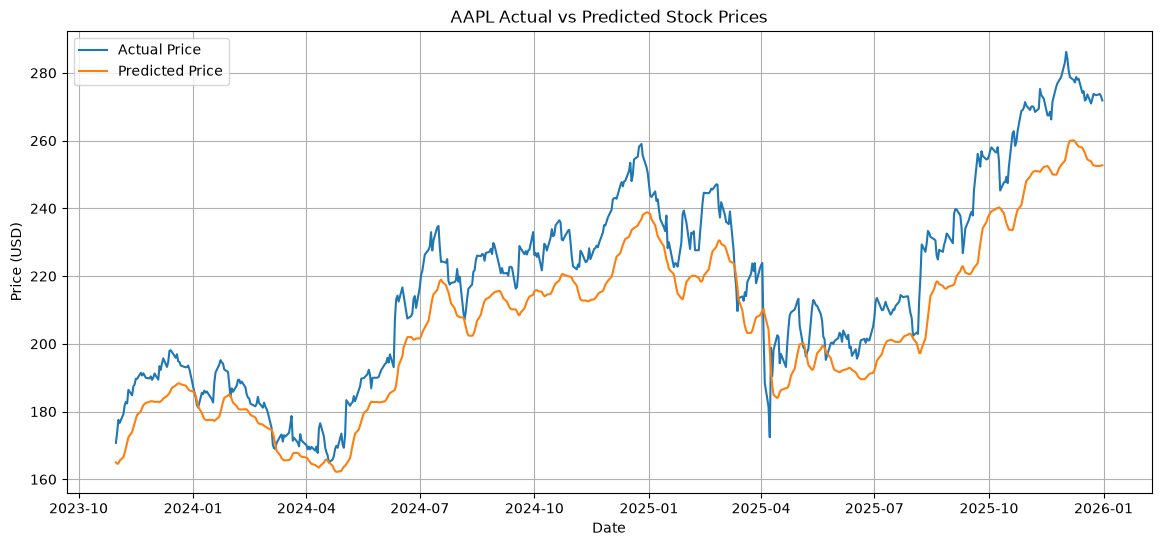

In [33]:
test_dates = df.index[train_size:]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    actual_prices.flatten(),
    label="Actual Price"
)

plt.plot(
    test_dates,
    predictions.flatten(),
    label="Predicted Price"
)

plt.title("AAPL Actual vs Predicted Stock Prices")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(True)
plt.show()

In [34]:
prediction_results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Price": actual_prices.flatten(),
    "Predicted_Price": predictions.flatten()
})

prediction_results.head(10)

,Date,Actual_Price,Predicted_Price
0,2023-10-31,170.770004,165.028183
1,2023-11-01,173.970001,164.569931
2,2023-11-02,177.570007,164.703705
3,2023-11-03,176.649994,165.523987
4,2023-11-06,179.229996,166.506378
5,2023-11-07,181.820007,167.766144
6,2023-11-08,182.889999,169.307617
7,2023-11-09,182.410004,170.933472
8,2023-11-10,186.399994,172.364975
9,2023-11-13,184.800003,173.978271


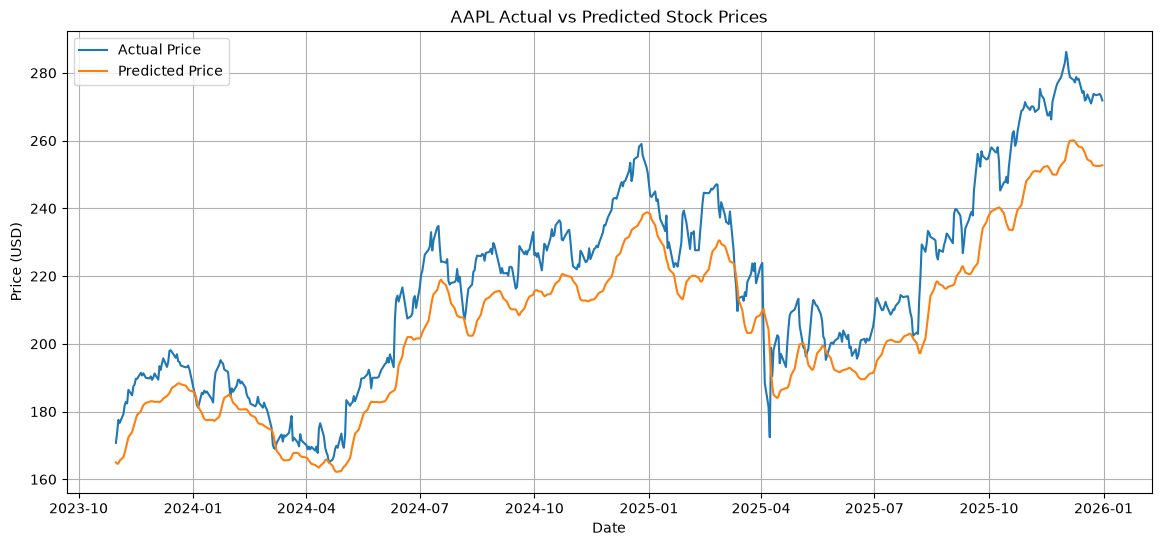

In [35]:
test_dates = df.index[train_size:]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    actual_prices.flatten(),
    label="Actual Price"
)

plt.plot(
    test_dates,
    predictions.flatten(),
    label="Predicted Price"
)

plt.title("AAPL Actual vs Predicted Stock Prices")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(True)
plt.show()

In [36]:
prediction_results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Price": actual_prices.flatten(),
    "Predicted_Price": predictions.flatten()
})

prediction_results.head(10)

,Date,Actual_Price,Predicted_Price
0,2023-10-31,170.770004,165.028183
1,2023-11-01,173.970001,164.569931
2,2023-11-02,177.570007,164.703705
3,2023-11-03,176.649994,165.523987
4,2023-11-06,179.229996,166.506378
5,2023-11-07,181.820007,167.766144
6,2023-11-08,182.889999,169.307617
7,2023-11-09,182.410004,170.933472
8,2023-11-10,186.399994,172.364975
9,2023-11-13,184.800003,173.978271


In [37]:
prediction_results["Error"] = (
    prediction_results["Actual_Price"]
    - prediction_results["Predicted_Price"]
)

prediction_results["Absolute_Error"] = (
    prediction_results["Error"].abs()
)

prediction_results.head()

,Date,Actual_Price,Predicted_Price,Error,Absolute_Error
0,2023-10-31,170.770004,165.028183,5.741821,5.741821
1,2023-11-01,173.970001,164.569931,9.400070,9.400070
2,2023-11-02,177.570007,164.703705,12.866302,12.866302
3,2023-11-03,176.649994,165.523987,11.126007,11.126007
4,2023-11-06,179.229996,166.506378,12.723618,12.723618


In [38]:
baseline_predictions = test_data[:-1].flatten()
baseline_actual = test_data[1:].flatten()

In [39]:
baseline_mae = mean_absolute_error(
    baseline_actual,
    baseline_predictions
)

print("Baseline MAE:", baseline_mae)

Baseline MAE: 2.416887624048616


In [40]:
baseline_rmse = np.sqrt(
    mean_squared_error(
        baseline_actual,
        baseline_predictions
    )
)

print("Baseline RMSE:", baseline_rmse)

Baseline RMSE: 3.5734766117445216


In [ ]:
results = pd.DataFrame({
    "Model": [
        "LSTM",
        "Naive Baseline"
    ],
    "MAE": [
        mae,
        baseline_mae
    ],
    "RMSE": [
        rmse,
        baseline_rmse
    ]
})

results

NameError: name 'MAE' is not defined

In [43]:
baseline_mae = mean_absolute_error(
    baseline_actual,
    baseline_predictions
)

print("Baseline MAE:", baseline_mae)

Baseline MAE: 2.416887624048616


In [44]:
baseline_rmse = np.sqrt(
    mean_squared_error(
        baseline_actual,
        baseline_predictions
    )
)

print("Baseline RMSE:", baseline_rmse)

Baseline RMSE: 3.5734766117445216


In [45]:
results = pd.DataFrame({
    "Model": [
        "LSTM",
        "Naive Baseline"
    ],
    "MAE": [
        mae,
        baseline_mae
    ],
    "RMSE": [
        rmse,
        baseline_rmse
    ]
})

results

NameError: name 'mae' is not defined

In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MAE:", mae)
print("RMSE:", rmse)


NameError: name 'y_test' is not defined

In [47]:
%whos

Variable               Type               Data/Info
---------------------------------------------------
MinMaxScaler           type               <class 'sklearn.preproces<...>sing._data.MinMaxScaler'>
X_test                 ndarray            544x60x1: 32640 elems, type `float64`, 261120 bytes (255.0 kb)
X_train                ndarray            2113x60x1: 126780 elems, type `float64`, 1014240 bytes (990.46875 kb)
actual_prices          ndarray            544x1: 544 elems, type `float64`, 4352 bytes
baseline_actual        ndarray            543: 543 elems, type `float64`, 4344 bytes
baseline_mae           float              2.416887624048616
baseline_predictions   ndarray            543: 543 elems, type `float64`, 4344 bytes
baseline_rmse          float64            3.5734766117445216
combined_data          ndarray            604x1: 604 elems, type `float64`, 4832 bytes
combined_scaled        ndarray            604x1: 604 elems, type `float64`, 4832 bytes
df                     DataFr

In [48]:
mae = mean_absolute_error(actual_prices, predictions)
rmse = np.sqrt(mean_squared_error(actual_prices, predictions))

print("LSTM MAE:", mae)
print("LSTM RMSE:", rmse)


LSTM MAE: 12.316057962529799
LSTM RMSE: 13.905162758198731


In [49]:
results = pd.DataFrame({
    "Model": [
        "LSTM",
        "Naive Baseline"
    ],
    "MAE": [
        mae,
        baseline_mae
    ],
    "RMSE": [
        rmse,
        baseline_rmse
    ]
})

results

,Model,MAE,RMSE
0,LSTM,12.316058,13.905163
1,Naive Baseline,2.416888,3.573477


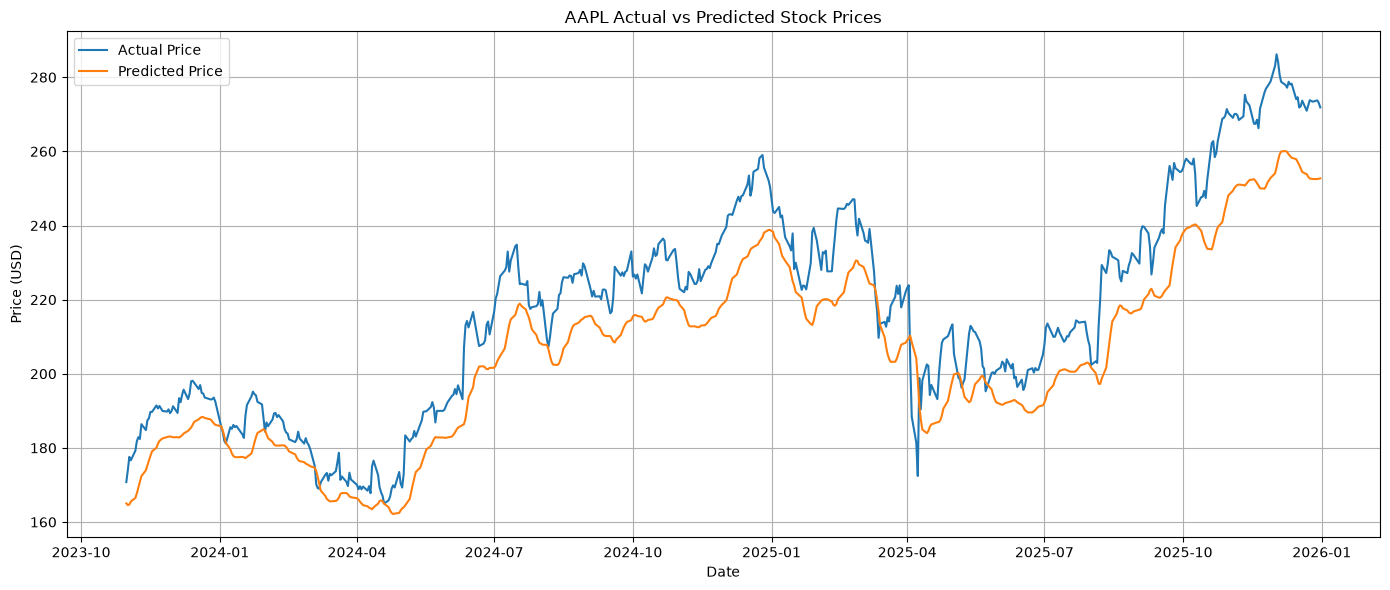

In [50]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    actual_prices.flatten(),
    label="Actual Price"
)

plt.plot(
    test_dates,
    predictions.flatten(),
    label="Predicted Price"
)

plt.title("AAPL Actual vs Predicted Stock Prices")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("../images/actual_vs_predicted.png", dpi=300)

plt.show()

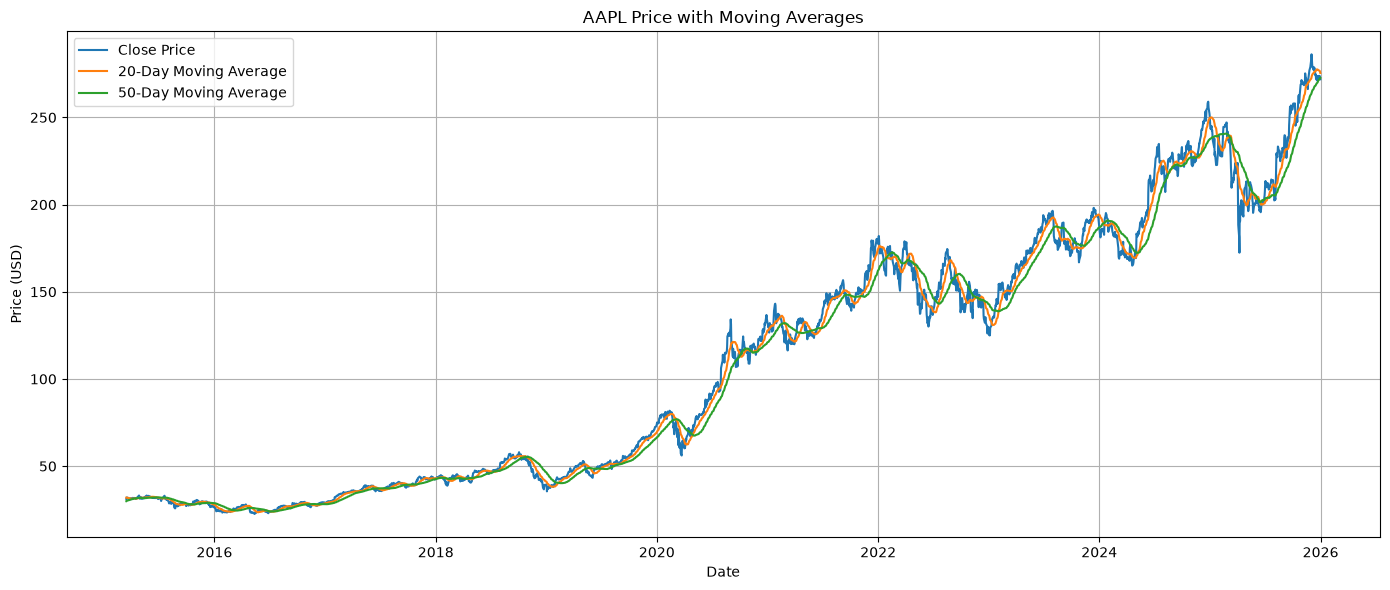

In [51]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Close"], label="Close Price")
plt.plot(df.index, df["MA20"], label="20-Day Moving Average")
plt.plot(df.index, df["MA50"], label="50-Day Moving Average")

plt.title("AAPL Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (USD)")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("../images/moving_averages.png", dpi=300)

plt.show()

In [52]:
print("LSTM MAE:", mae)
print("Baseline MAE:", baseline_mae)

print("\nLSTM RMSE:", rmse)
print("Baseline RMSE:", baseline_rmse)


LSTM MAE: 12.316057962529799
Baseline MAE: 2.416887624048616

LSTM RMSE: 13.905162758198731
Baseline RMSE: 3.5734766117445216


In [53]:
mae_difference = ((mae - baseline_mae) / baseline_mae) * 100
rmse_difference = ((rmse - baseline_rmse) / baseline_rmse) * 100

print(f"\nLSTM MAE relative to baseline: {mae_difference:.2f}%")
print(f"LSTM RMSE relative to baseline: {rmse_difference:.2f}%")


LSTM MAE relative to baseline: 409.58%
LSTM RMSE relative to baseline: 289.12%


In [55]:
features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "MA20",
    "MA50"
]

model_df = df[features].dropna().copy()

model_df.head()

Price,Open,High,Low,Close,Volume,Daily_Return,MA20,MA50
Date,,,,,,,,
2015-03-16,30.969999,31.237499,30.717501,31.237499,143497200,0.011004,31.927750,29.91460
2015-03-17,31.475000,31.830000,31.412500,31.760000,204092400,0.016727,31.917875,30.00315
2015-03-18,31.750000,32.290001,31.592501,32.117500,261083600,0.011256,31.914750,30.11425
2015-03-19,32.187500,32.312500,31.850000,31.875000,183238000,-0.007550,31.902875,30.22045
2015-03-20,32.062500,32.099998,31.290001,31.475000,274780400,-0.012549,31.857875,30.31120


In [56]:
features = model_df.values

print("Feature matrix shape:", features.shape)


Feature matrix shape: (2717, 8)


In [57]:
train_size_multi = int(len(features) * 0.8)

train_multi = features[:train_size_multi]
test_multi = features[train_size_multi:]

print("Training shape:", train_multi.shape)
print("Testing shape:", test_multi.shape)

Training shape: (2173, 8)
Testing shape: (544, 8)


In [58]:
multi_scaler = MinMaxScaler(feature_range=(0, 1))

train_multi_scaled = multi_scaler.fit_transform(train_multi)
test_multi_scaled = multi_scaler.transform(test_multi)

print("Scaled training shape:", train_multi_scaled.shape)

Scaled training shape: (2173, 8)


In [59]:
lookback = 60

X_train_multi = []
y_train_multi = []

close_index = features_list = features = model_df.columns.get_loc("Close")

for i in range(lookback, len(train_multi_scaled)):
    X_train_multi.append(
        train_multi_scaled[i-lookback:i, :]
    )
    y_train_multi.append(
        train_multi_scaled[i, close_index]
    )

X_train_multi = np.array(X_train_multi)
y_train_multi = np.array(y_train_multi)

print("X_train_multi shape:", X_train_multi.shape)
print("y_train_multi shape:", y_train_multi.shape)

X_train_multi shape: (2113, 60, 8)
y_train_multi shape: (2113,)


In [60]:
multi_model = keras.Sequential([
    keras.layers.Input(shape=(lookback, X_train_multi.shape[2])),

    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.LSTM(64),

    keras.layers.Dense(32),
    keras.layers.Dropout(0.2),

    keras.layers.Dense(1)
])

multi_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 60, 64)         │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,825 (210.25 KB)

 Trainable params: 53,825 (210.25 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
multi_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

In [62]:
multi_history = multi_model.fit(
    X_train_multi,
    y_train_multi,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 18s 124ms/step - loss: 0.0072 - val_loss: 0.0015
Epoch 2/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - loss: 0.0024 - val_loss: 0.0012
Epoch 3/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - loss: 0.0021 - val_loss: 0.0049
Epoch 4/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - loss: 0.0022 - val_loss: 0.0011
Epoch 5/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - loss: 0.0019 - val_loss: 8.0702e-04
Epoch 6/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - loss: 0.0020 - val_loss: 9.4567e-04
Epoch 7/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - loss: 0.0020 - val_loss: 7.3575e-04
Epoch 8/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 82ms/step - loss: 0.0019 - val_loss: 0.0017
Epoch 9/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - loss: 0.0018 - val_loss: 0.0039
Epoch 10/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - loss: 0.0019 - val_loss: 0.0012
Epoch 11/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - loss: 0.0018 - val_loss: 0.0032
Epoch 12/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/st

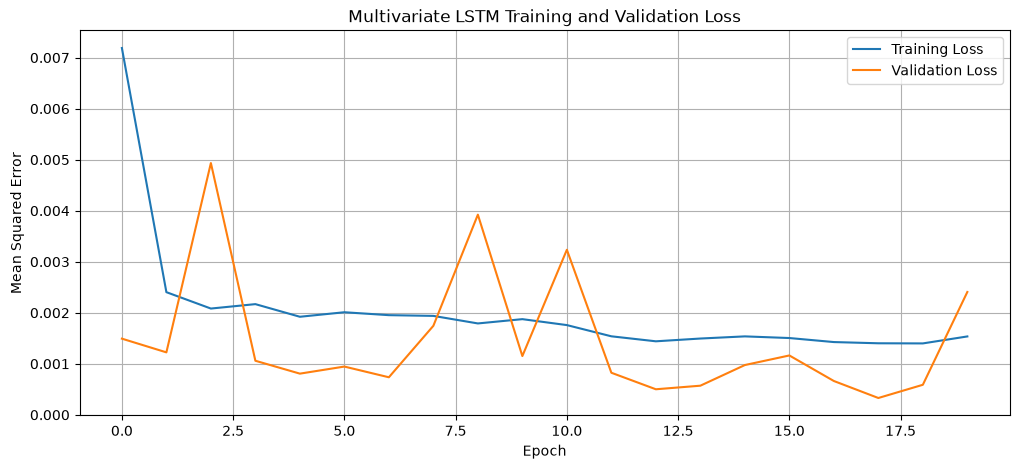

In [63]:
plt.figure(figsize=(12, 5))

plt.plot(
    multi_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    multi_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Multivariate LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.grid(True)
plt.show()

In [64]:
# Prepare test sequences using the final 60 training observations
combined_multi = np.concatenate(
    (train_multi[-lookback:], test_multi),
    axis=0
)

combined_multi_scaled = multi_scaler.transform(combined_multi)

X_test_multi = []

for i in range(lookback, len(combined_multi_scaled)):
    X_test_multi.append(
        combined_multi_scaled[i-lookback:i, :]
    )

X_test_multi = np.array(X_test_multi)

print("X_test_multi shape:", X_test_multi.shape)

X_test_multi shape: (544, 60, 8)


In [65]:
predictions_multi_scaled = multi_model.predict(X_test_multi)

print("Prediction shape:", predictions_multi_scaled.shape)

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
Prediction shape: (544, 1)


In [66]:
# Create a dummy array for inverse transformation
dummy = np.zeros(
    (len(predictions_multi_scaled), train_multi_scaled.shape[1])
)

dummy[:, close_index] = predictions_multi_scaled.flatten()

predictions_multi = multi_scaler.inverse_transform(dummy)[:, close_index]

# Actual closing prices
actual_multi = test_multi[:, close_index]

print("First 5 predicted prices:")
print(predictions_multi[:5])

print("\nFirst 5 actual prices:")
print(actual_multi[:5])

First 5 predicted prices:
[162.39668992 162.58353772 163.73285378 165.54521526 166.05622276]

First 5 actual prices:
[170.77000427 173.97000122 177.57000732 176.6499939  179.22999573]


In [67]:
multi_mae = mean_absolute_error(
    actual_multi,
    predictions_multi
)

multi_rmse = np.sqrt(
    mean_squared_error(
        actual_multi,
        predictions_multi
    )
)

print("Multivariate LSTM MAE:", multi_mae)
print("Multivariate LSTM RMSE:", multi_rmse)

Multivariate LSTM MAE: 18.908016568236302
Multivariate LSTM RMSE: 20.965701504634385


In [1]:
plt.figure(figsize=(14, 6))

plt.plot(
    actual_multi,
    label="Actual Price"
)

plt.plot(
    predictions_multi,
    label="Multivariate LSTM Prediction"
)

plt.title("AAPL Actual vs Multivariate LSTM Predicted Prices")
plt.xlabel("Test Period")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)

plt.show()

NameError: name 'plt' is not defined

In [2]:
import matplotlib.pyplot as plt

In [3]:
plt.figure(figsize=(14, 6))

plt.plot(
    actual_multi,
    label="Actual Price"
)

plt.plot(
    predictions_multi,
    label="Multivariate LSTM Prediction"
)

plt.title("AAPL Actual vs Multivariate LSTM Predicted Prices")
plt.xlabel("Test Period")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)

plt.show()

NameError: name 'actual_multi' is not defined

<Figure size 1400x600 with 0 Axes>

In [4]:
lookback = 60

combined_multi = np.concatenate(
    (train_multi[-lookback:], test_multi),
    axis=0
)

combined_multi_scaled = multi_scaler.transform(combined_multi)

X_test_multi = []

for i in range(lookback, len(combined_multi_scaled)):
    X_test_multi.append(
        combined_multi_scaled[i-lookback:i, :]
    )

X_test_multi = np.array(X_test_multi)

print("X_test_multi shape:", X_test_multi.shape)

NameError: name 'np' is not defined

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow import keras

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [6]:
ticker = "AAPL"

df = yf.download(
    ticker,
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=False
)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df["Daily_Return"] = df["Close"].pct_change()
df["MA20"] = df["Close"].rolling(window=20).mean()
df["MA50"] = df["Close"].rolling(window=50).mean()

df = df.dropna().copy()

print("Data shape:", df.shape)

NameError: name 'yf' is not defined

In [7]:
import yfinance as yf

In [8]:
ticker = "AAPL"

df = yf.download(
    ticker,
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=False
)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df["Daily_Return"] = df["Close"].pct_change()
df["MA20"] = df["Close"].rolling(window=20).mean()
df["MA50"] = df["Close"].rolling(window=50).mean()

df = df.dropna().copy()

print("Data shape:", df.shape)

[*********************100%***********************]  1 of 1 completed

Data shape: (2717, 9)


In [9]:
features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "MA20",
    "MA50"
]

model_df = df[features].dropna().copy()

# Make sure column names are simple strings
model_df.columns = [
    col[-1] if isinstance(col, tuple) else col
    for col in model_df.columns
]

features_array = model_df.values

print("Feature matrix shape:", features_array.shape)
print("Features:", list(model_df.columns))

Feature matrix shape: (2717, 8)
Features: ['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'MA20', 'MA50']


In [10]:
train_size_multi = int(len(features_array) * 0.8)

train_multi = features_array[:train_size_multi]
test_multi = features_array[train_size_multi:]

multi_scaler = MinMaxScaler(feature_range=(0, 1))

train_multi_scaled = multi_scaler.fit_transform(train_multi)
test_multi_scaled = multi_scaler.transform(test_multi)

close_index = model_df.columns.get_loc("Close")

print("Training shape:", train_multi.shape)
print("Testing shape:", test_multi.shape)
print("Close index:", close_index)

Training shape: (2173, 8)
Testing shape: (544, 8)
Close index: 3


In [11]:
lookback = 60

multi_model = keras.Sequential([
    keras.layers.Input(shape=(lookback, 8)),
    keras.layers.LSTM(64, return_sequences=True),
    keras.layers.LSTM(64),
    keras.layers.Dense(32),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1)
])

multi_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

multi_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,825 (210.25 KB)

 Trainable params: 53,825 (210.25 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
lookback = 60

X_train_multi = []
y_train_multi = []

for i in range(lookback, len(train_multi_scaled)):
    X_train_multi.append(
        train_multi_scaled[i-lookback:i, :]
    )
    y_train_multi.append(
        train_multi_scaled[i, close_index]
    )

X_train_multi = np.array(X_train_multi)
y_train_multi = np.array(y_train_multi)

print("X_train_multi shape:", X_train_multi.shape)
print("y_train_multi shape:", y_train_multi.shape)

X_train_multi shape: (2113, 60, 8)
y_train_multi shape: (2113,)


In [13]:
multi_history = multi_model.fit(
    X_train_multi,
    y_train_multi,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 24s 146ms/step - loss: 0.0136 - val_loss: 0.0016
Epoch 2/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step - loss: 0.0030 - val_loss: 0.0038
Epoch 3/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 11s 189ms/step - loss: 0.0028 - val_loss: 0.0068
Epoch 4/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 24s 238ms/step - loss: 0.0025 - val_loss: 0.0037
Epoch 5/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 15s 147ms/step - loss: 0.0021 - val_loss: 0.0018
Epoch 6/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 11s 178ms/step - loss: 0.0019 - val_loss: 7.5057e-04
Epoch 7/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 123ms/step - loss: 0.0020 - val_loss: 0.0071
Epoch 8/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - loss: 0.0023 - val_loss: 0.0040
Epoch 9/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - loss: 0.0017 - val_loss: 0.0014
Epoch 10/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - loss: 0.0020 - val_loss: 0.0058
Epoch 11/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 94ms/step - loss: 0.0017 - val_loss: 5.9705e-04
Epoch 12/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 

In [14]:
combined_multi = np.concatenate(
    (train_multi[-lookback:], test_multi),
    axis=0
)

combined_multi_scaled = multi_scaler.transform(combined_multi)

X_test_multi = []

for i in range(lookback, len(combined_multi_scaled)):
    X_test_multi.append(
        combined_multi_scaled[i-lookback:i, :]
    )

X_test_multi = np.array(X_test_multi)

print("X_test_multi shape:", X_test_multi.shape)

X_test_multi shape: (544, 60, 8)


In [15]:
predictions_multi_scaled = multi_model.predict(X_test_multi)

print("Prediction shape:", predictions_multi_scaled.shape)

17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
Prediction shape: (544, 1)


In [16]:
dummy = np.zeros(
    (len(predictions_multi_scaled), train_multi_scaled.shape[1])
)

dummy[:, close_index] = predictions_multi_scaled.flatten()

predictions_multi = multi_scaler.inverse_transform(
    dummy
)[:, close_index]

actual_multi = test_multi[:, close_index]

print("Predictions:", predictions_multi[:5])
print("Actual:", actual_multi[:5])

Predictions: [161.68825384 161.53164575 162.11738199 163.43104743 164.13786685]
Actual: [170.77000427 173.97000122 177.57000732 176.6499939  179.22999573]


In [17]:
multi_mae = mean_absolute_error(
    actual_multi,
    predictions_multi
)

multi_rmse = np.sqrt(
    mean_squared_error(
        actual_multi,
        predictions_multi
    )
)

print("Multivariate LSTM MAE:", multi_mae)
print("Multivariate LSTM RMSE:", multi_rmse)

Multivariate LSTM MAE: 18.824637913124956
Multivariate LSTM RMSE: 20.545174104153194


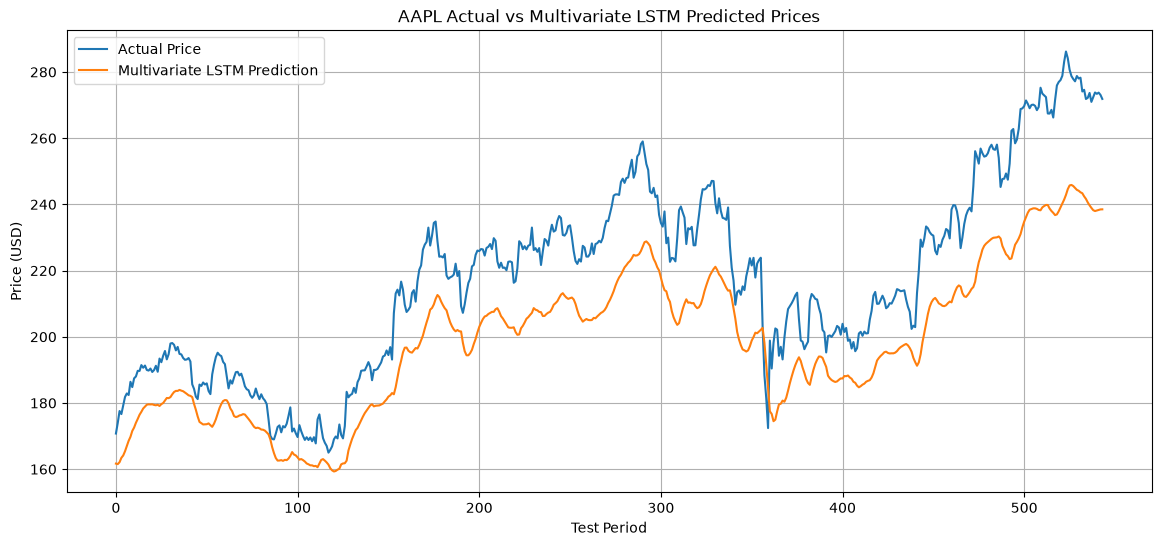

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(
    actual_multi,
    label="Actual Price"
)

plt.plot(
    predictions_multi,
    label="Multivariate LSTM Prediction"
)

plt.title("AAPL Actual vs Multivariate LSTM Predicted Prices")
plt.xlabel("Test Period")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)

plt.savefig(
    "../images/multivariate_lstm_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Univariate LSTM",
        "Multivariate LSTM"
    ],
    "MAE": [
        baseline_mae,
        mae,
        multi_mae
    ],
    "RMSE": [
        baseline_rmse,
        rmse,
        multi_rmse
    ]
})

comparison

NameError: name 'baseline_mae' is not defined

In [20]:
comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Univariate LSTM",
        "Multivariate LSTM"
    ],
    "MAE": [
        2.416887624048616,
        12.316058,
        multi_mae
    ],
    "RMSE": [
        3.5734766117445216,
        13.905163,
        multi_rmse
    ]
})

comparison

,Model,MAE,RMSE
0,Naive Baseline,2.416888,3.573477
1,Univariate LSTM,12.316058,13.905163
2,Multivariate LSTM,18.824638,20.545174


In [21]:
comparison.to_csv(
    "../data/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


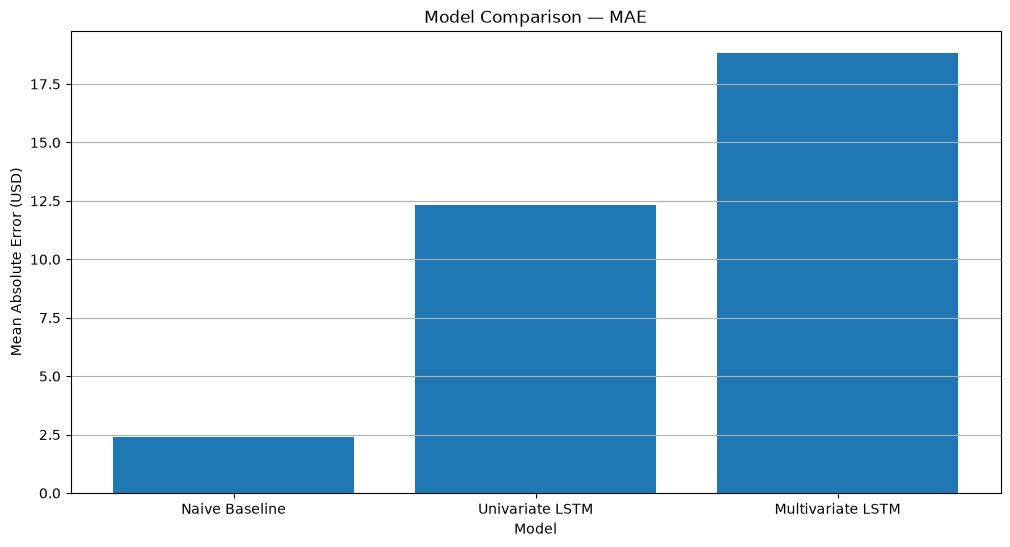

In [22]:
plt.figure(figsize=(12, 6))

plt.bar(comparison["Model"], comparison["MAE"])

plt.title("Model Comparison — MAE")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (USD)")
plt.grid(axis="y")

plt.savefig(
    "../images/model_comparison_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

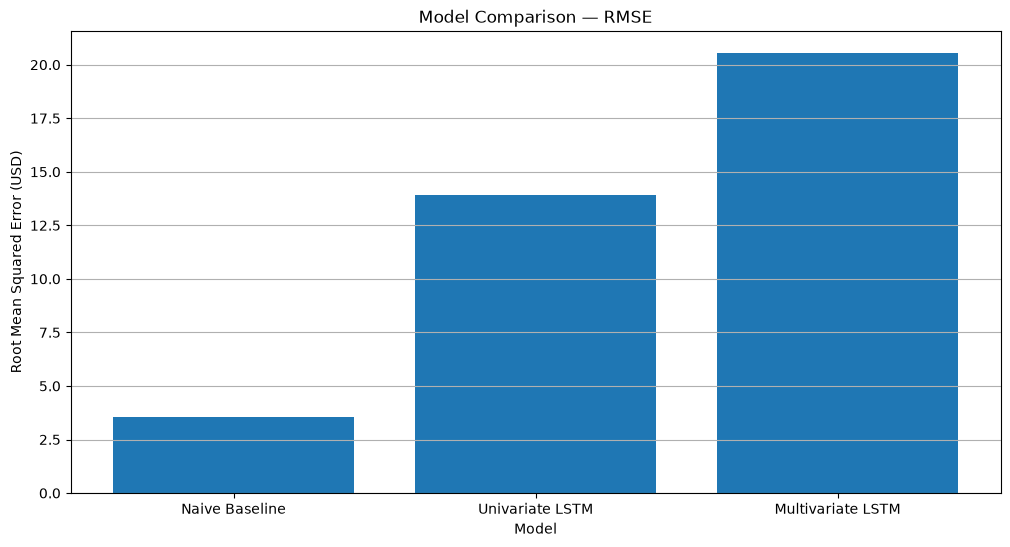

In [23]:
plt.figure(figsize=(12, 6))

plt.bar(comparison["Model"], comparison["RMSE"])

plt.title("Model Comparison — RMSE")
plt.xlabel("Model")
plt.ylabel("Root Mean Squared Error (USD)")
plt.grid(axis="y")

plt.savefig(
    "../images/model_comparison_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

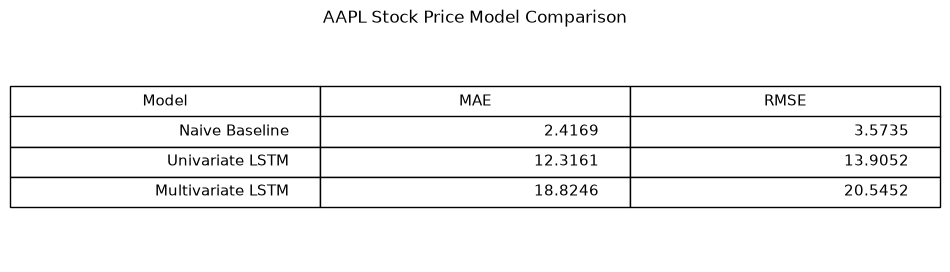

In [24]:
fig, ax = plt.subplots(figsize=(10, 3))

ax.axis("off")

table = ax.table(
    cellText=comparison.round(4).values,
    colLabels=comparison.columns,
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.8)

plt.title("AAPL Stock Price Model Comparison")

plt.savefig(
    "../images/model_comparison_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Findings

Three forecasting approaches were evaluated on the AAPL test dataset:

1. Naive Baseline
2. Univariate LSTM
3. Multivariate LSTM

The results were:

| Model | MAE | RMSE |
|---|---:|---:|
| Naive Baseline | 2.4169 | 3.5735 |
| Univariate LSTM | 12.3161 | 13.9052 |
| Multivariate LSTM | 18.8246 | 20.5452 |

The Naive Baseline achieved the lowest MAE and RMSE, outperforming both LSTM models on the test period.

The Univariate LSTM performed better than the Multivariate LSTM, although both were less accurate than the simple baseline.

This demonstrates an important machine learning principle: a more complex model does not automatically produce better predictions. Establishing a simple baseline is essential for determining whether a machine learning model provides meaningful improvement.

# Limitations

This project has several limitations:

- The model uses historical price and volume information only.
- Stock prices are influenced by external factors such as news, market sentiment, economic conditions, and company fundamentals.
- The models were evaluated using a single chronological train/test split.
- Hyperparameter tuning was limited.
- No transaction costs, trading fees, or slippage were included.
- The project predicts price levels rather than directly optimizing investment returns.
- Historical performance does not guarantee future market performance.

These limitations mean the models should be considered educational forecasting experiments rather than financial advice or production trading systems.

# Future Improvements

Future versions of this project could explore:

- Walk-forward and rolling-window validation
- Hyperparameter optimization
- Predicting returns instead of raw prices
- Additional technical indicators
- Market indices and macroeconomic variables
- News and sentiment data
- XGBoost and Random Forest models
- Transformer-based time-series models
- More extensive feature engineering
- Proper backtesting with transaction costs

# Conclusion

This project investigated whether LSTM neural networks could improve AAPL stock price forecasting compared with a simple naive baseline.

Although the LSTM models were capable of learning patterns from historical price data, neither the univariate nor multivariate LSTM outperformed the naive baseline on the selected test period.

The Naive Baseline achieved the best performance with an MAE of 2.4169 and an RMSE of 3.5735.

The main takeaway is that model complexity alone does not guarantee better predictive performance. Comparing machine learning models against simple benchmarks is therefore an important part of responsible model evaluation.

The project also provided practical experience with data collection, exploratory data analysis, feature engineering, time-series preprocessing, feature scaling, LSTM neural networks, model evaluation, and communicating machine learning results.